In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:
# Load the MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


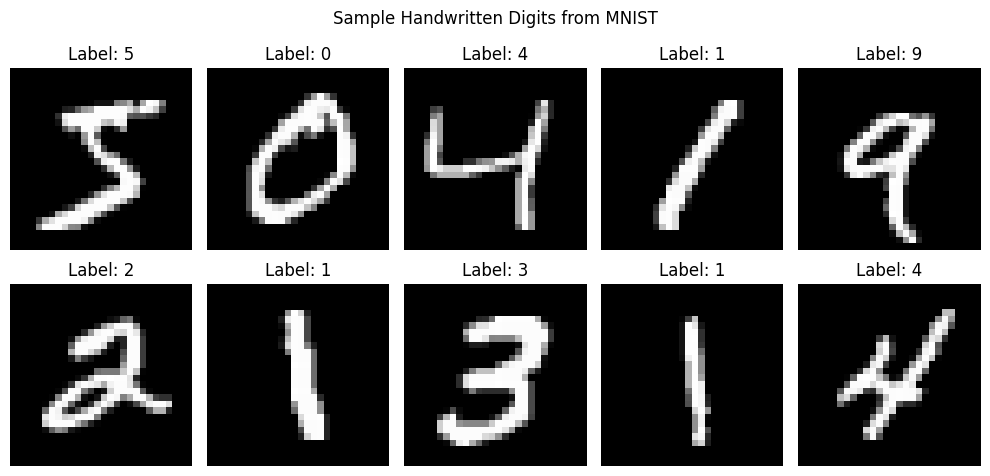

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Handwritten Digits from MNIST")
plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values from 0–255 to 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add a channel dimension for the CNN
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [ ]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Learn image patterns
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert extracted features into a classification
    layers.Flatten(),
    layers.Dense(64, activation="relu"),

    # 10 output classes: digits 0 to 9
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 60s 68ms/step - accuracy: 0.9468 - loss: 0.1812 - val_accuracy: 0.9867 - val_loss: 0.0530
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9836 - loss: 0.0533 - val_accuracy: 0.9835 - val_loss: 0.0533
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9881 - loss: 0.0389 - val_accuracy: 0.9877 - val_loss: 0.0381
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9905 - loss: 0.0291 - val_accuracy: 0.9895 - val_loss: 0.0393
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9921 - loss: 0.0232 - val_accuracy: 0.9883 - val_loss: 0.0412


In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0416
Test Accuracy: 98.58%


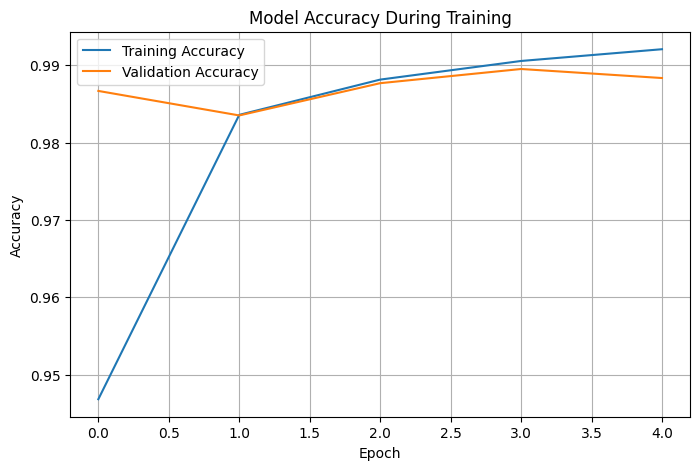

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

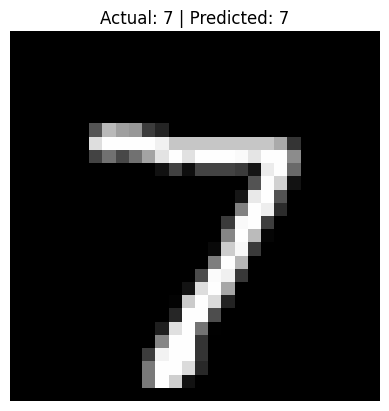

Actual digit: 7
Predicted digit: 7
Model confidence: 100.00%


In [ ]:
# Select one test image
index = 0

image = X_test[index]
actual_digit = y_test[index]

# Predict the digit
prediction = model.predict(image[np.newaxis, ...], verbose=0)
predicted_digit = np.argmax(prediction[0])

# Display the image and prediction
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {actual_digit} | Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

print("Actual digit:", actual_digit)
print("Predicted digit:", predicted_digit)
print(f"Model confidence: {prediction[0][predicted_digit] * 100:.2f}%")

In [ ]:
y_probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_probabilities, axis=1)

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9908    0.9929    0.9918       980
           1     0.9810    0.9982    0.9895      1135
           2     0.9941    0.9729    0.9833      1032
           3     0.9710    0.9950    0.9829      1010
           4     0.9889    0.9959    0.9924       982
           5     0.9713    0.9877    0.9794       892
           6     0.9947    0.9770    0.9858       958
           7     0.9806    0.9854    0.9830      1028
           8     0.9917    0.9856    0.9887       974
           9     0.9949    0.9663    0.9804      1009

    accuracy                         0.9858     10000
   macro avg     0.9859    0.9857    0.9857     10000
weighted avg     0.9859    0.9858    0.9858     10000



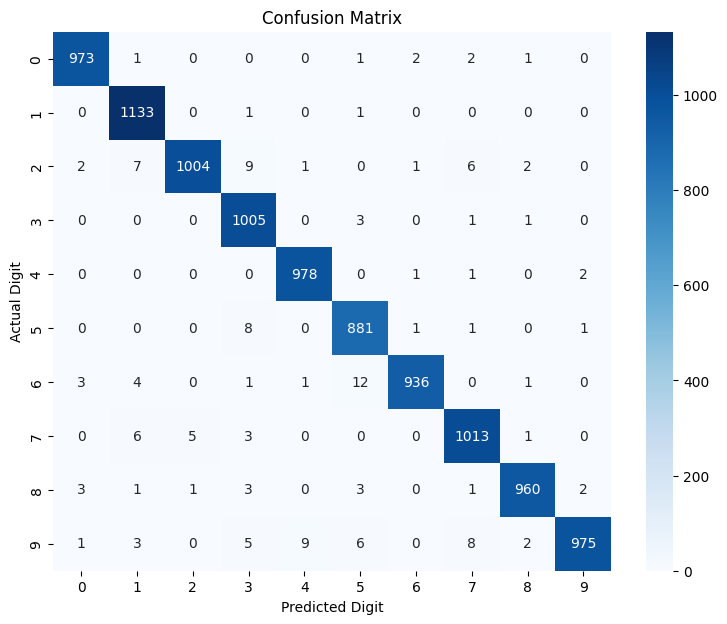

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

In [ ]:
model.save("handwritten_digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Evaluate the trained model on unseen test images

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0416
Test Accuracy: 98.58%


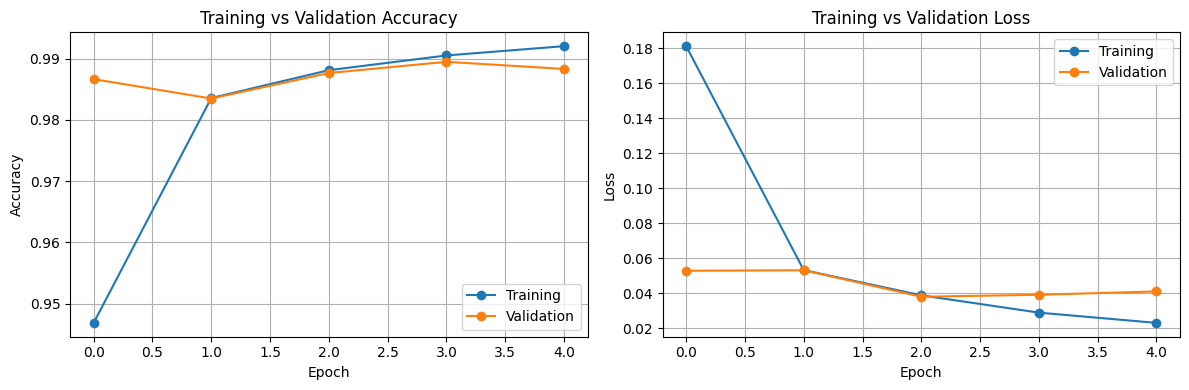

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generate predictions for all test images
probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

# Find indices where predictions are incorrect
wrong_indices = np.where(y_pred != y_test)[0]

print("Total test images:", len(y_test))
print("Incorrect predictions:", len(wrong_indices))
print("Correct predictions:", len(y_test) - len(wrong_indices))

Total test images: 10000
Incorrect predictions: 142
Correct predictions: 9858


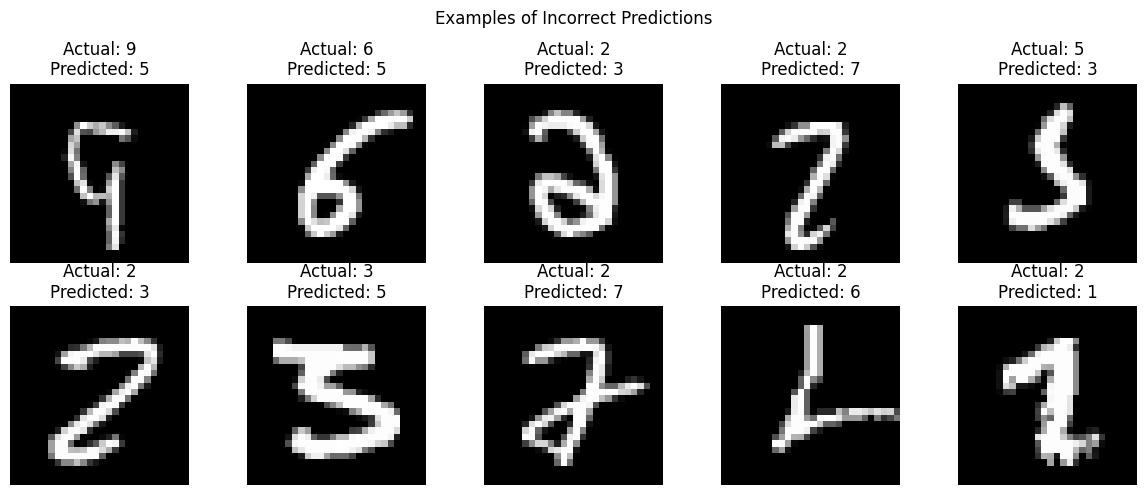

In [ ]:
if len(wrong_indices) > 0:
    n = min(10, len(wrong_indices))

    plt.figure(figsize=(12, 5))

    for i in range(n):
        idx = wrong_indices[i]

        plt.subplot(2, 5, i + 1)
        plt.imshow(X_test[idx].squeeze(), cmap="gray")
        plt.title(
            f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}"
        )
        plt.axis("off")

    plt.suptitle("Examples of Incorrect Predictions")
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found.")

              precision    recall  f1-score   support

           0     0.9908    0.9929    0.9918       980
           1     0.9810    0.9982    0.9895      1135
           2     0.9941    0.9729    0.9833      1032
           3     0.9710    0.9950    0.9829      1010
           4     0.9889    0.9959    0.9924       982
           5     0.9713    0.9877    0.9794       892
           6     0.9947    0.9770    0.9858       958
           7     0.9806    0.9854    0.9830      1028
           8     0.9917    0.9856    0.9887       974
           9     0.9949    0.9663    0.9804      1009

    accuracy                         0.9858     10000
   macro avg     0.9859    0.9857    0.9857     10000
weighted avg     0.9859    0.9858    0.9858     10000



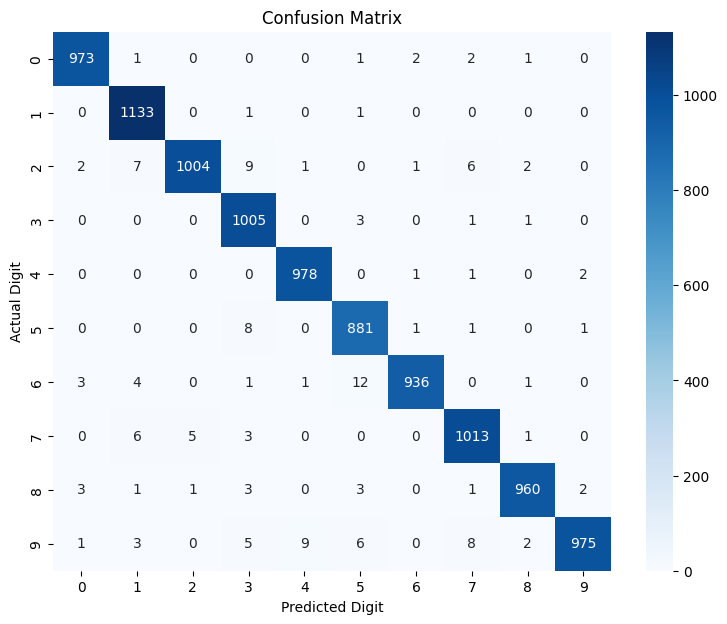

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# Display the training history for each epoch

for i in range(len(history.history["accuracy"])):
    print(f"\nEpoch {i + 1}")
    print(f"Training accuracy:   {history.history['accuracy'][i] * 100:.2f}%")
    print(f"Validation accuracy: {history.history['val_accuracy'][i] * 100:.2f}%")
    print(f"Training loss:       {history.history['loss'][i]:.4f}")
    print(f"Validation loss:     {history.history['val_loss'][i]:.4f}")


Epoch 1
Training accuracy:   94.68%
Validation accuracy: 98.67%
Training loss:       0.1812
Validation loss:     0.0530

Epoch 2
Training accuracy:   98.36%
Validation accuracy: 98.35%
Training loss:       0.0533
Validation loss:     0.0533

Epoch 3
Training accuracy:   98.81%
Validation accuracy: 98.77%
Training loss:       0.0389
Validation loss:     0.0381

Epoch 4
Training accuracy:   99.05%
Validation accuracy: 98.95%
Training loss:       0.0291
Validation loss:     0.0393

Epoch 5
Training accuracy:   99.21%
Validation accuracy: 98.83%
Training loss:       0.0232
Validation loss:     0.0412


In [ ]:
model.save("handwritten_digit_model.keras")

print("Final trained model saved successfully!")

Final trained model saved successfully!


In [ ]:
from google.colab import files

files.download("handwritten_digit_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

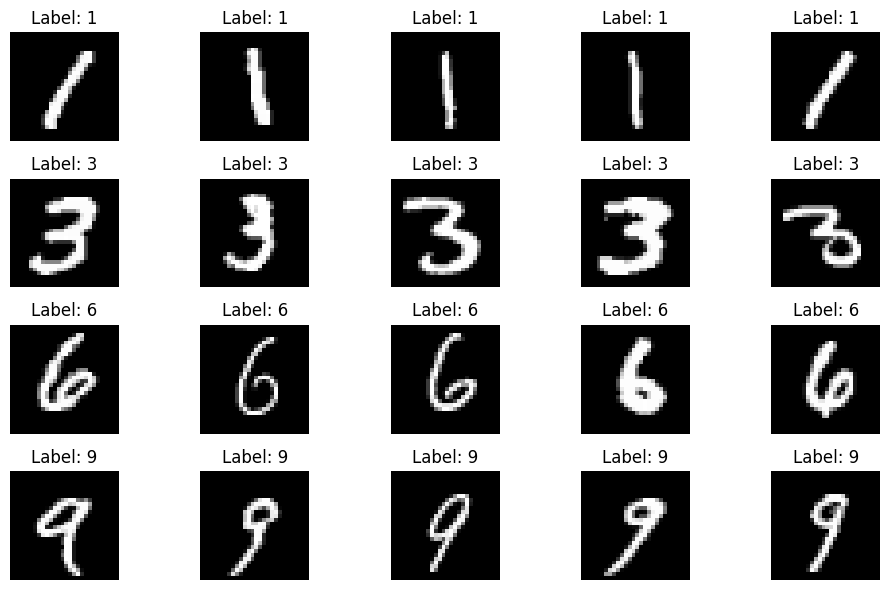

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Display sample training images of digits 1, 3, 6 and 9
digits = [1, 3, 6, 9]

plt.figure(figsize=(10, 6))

for row, digit in enumerate(digits):
    indices = np.where(y_train == digit)[0][:5]

    for col, idx in enumerate(indices):
        plt.subplot(len(digits), 5, row * 5 + col + 1)
        plt.imshow(X_train[idx], cmap="gray")
        plt.title(f"Label: {y_train[idx]}")
        plt.axis("off")

plt.tight_layout()
plt.show()